# 05 — Evaluación operativa y económica de la política de abastecimiento

**Caso Tostao | Política piloto Q90 | Horizonte de revisión: 7 días**

## Propósito
Evaluar las recomendaciones producidas por el Notebook 04 desde la perspectiva de operación y negocio:

- distribución de pedidos por tienda y producto;
- inventario actual frente a demanda pronosticada;
- combinaciones que requieren pedido y combinaciones con cobertura suficiente;
- concentración de unidades y valor de compra sugerido;
- sensibilidad de la decisión al límite de cobertura;
- diferencias entre Q85, Q90 y Q95;
- señales de riesgo de sobreinventario que puedan investigarse con operación.

**Alcance:** este análisis evalúa una política simplificada de revisión semanal. No estima ahorros realizados ni capacidad física de almacenamiento. Los valores económicos calculados con costo unitario representan valor de compra estimado, no flujo de caja definitivo ni costo total de inventario.


## 1. Archivos de entrada

Sube los archivos exportados por el Notebook 04 y los maestros originales:

1. `recomendacion_abastecimiento_Q90.csv`
2. `comparacion_politicas_Q85_Q90_Q95.csv`
3. `resumen_politicas_abastecimiento.csv`
4. `sensibilidad_cobertura_Q90.csv`
5. `forecast_ets_semanal_sku_tienda.csv`
6. `inventario_actual.csv`
7. `catalogo_productos.csv`
8. `maestro_tiendas.csv`

El notebook valida nombres, llaves y cardinalidad antes de calcular indicadores.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

KEYS = ["id_tienda", "id_producto"]
REQUIRED = [
    "recomendacion_abastecimiento_Q90.csv",
    "comparacion_politicas_Q85_Q90_Q95.csv",
    "resumen_politicas_abastecimiento.csv",
    "sensibilidad_cobertura_Q90.csv",
    "forecast_ets_semanal_sku_tienda.csv",
    "inventario_actual.csv",
    "catalogo_productos.csv",
    "maestro_tiendas.csv"
]

try:
    from google.colab import files
    missing = [f for f in REQUIRED if not Path("/content", f).exists() and not Path(f).exists()]
    if missing:
        print("Carga los archivos requeridos:", missing)
        files.upload()
except Exception:
    pass

def locate_file(name):
    for p in [Path("/content") / name, Path(name)]:
        if p.exists():
            return p
    raise FileNotFoundError(f"No se encontró {name}. Ejecuta primero el Notebook 04 y carga sus CSV.")

data = {Path(f).stem: pd.read_csv(locate_file(f)) for f in REQUIRED}

rec = data["recomendacion_abastecimiento_Q90"].copy()
policies = data["comparacion_politicas_Q85_Q90_Q95"].copy()
policy_summary = data["resumen_politicas_abastecimiento"].copy()
coverage = data["sensibilidad_cobertura_Q90"].copy()
forecast = data["forecast_ets_semanal_sku_tienda"].copy()
inventory = data["inventario_actual"].copy()
products = data["catalogo_productos"].copy()
stores = data["maestro_tiendas"].copy()

for name, df in {
    "recomendacion_Q90": rec, "comparacion_politicas": policies,
    "forecast_semanal": forecast, "inventario": inventory,
    "catalogo": products, "tiendas": stores
}.items():
    print(f"{name:25s} {df.shape}")


recomendacion_Q90         (160, 10)
comparacion_politicas     (480, 11)
forecast_semanal          (160, 3)
inventario                (160, 3)
catalogo                  (8, 6)
tiendas                   (20, 3)


## 2. Validación de integridad

Se comprueba que:
- las llaves SKU–Tienda no estén duplicadas;
- las recomendaciones tengan correspondencia con forecast e inventario;
- no existan pedidos negativos;
- las cantidades y costos utilizados sean numéricos.

Si falla una validación, se detiene el análisis para evitar reportar resultados inconsistentes.


In [ ]:
def assert_unique(df, keys, name):
    duplicated = df.duplicated(keys, keep=False)
    if duplicated.any():
        raise ValueError(f"{name}: hay {duplicated.sum()} filas en llaves duplicadas {keys}.")

for df, name in [(rec, "recomendación"), (forecast, "forecast"), (inventory, "inventario")]:
    assert_unique(df, KEYS, name)

required_rec = set(KEYS + ["pedido_sugerido", "inventario_objetivo", "stock_actual",
                           "demanda_pronosticada_7d", "politica"])
required_product = set(["id_producto", "costo_unitario", "precio_venta"])
required_store = set(["id_tienda", "ciudad", "tamaño_m2"])

if not required_rec.issubset(rec.columns):
    raise ValueError(f"Faltan columnas en recomendación: {required_rec - set(rec.columns)}")
if not required_product.issubset(products.columns):
    raise ValueError(f"Faltan columnas en catálogo: {required_product - set(products.columns)}")
if not required_store.issubset(stores.columns):
    raise ValueError(f"Faltan columnas en maestro tiendas: {required_store - set(stores.columns)}")

for col in ["pedido_sugerido", "inventario_objetivo", "stock_actual", "demanda_pronosticada_7d"]:
    rec[col] = pd.to_numeric(rec[col], errors="coerce")
    if rec[col].isna().any():
        raise ValueError(f"La columna {col} tiene valores nulos/no numéricos.")
if (rec["pedido_sugerido"] < 0).any():
    raise ValueError("Se encontraron pedidos negativos.")

print("Combinaciones recomendadas:", len(rec))
print("Combinaciones en forecast:", len(forecast))
print("Combinaciones en inventario:", len(inventory))
print("Política contenida:", rec["politica"].unique())


Combinaciones recomendadas: 160
Combinaciones en forecast: 160
Combinaciones en inventario: 160
Política contenida: ['Q90']


## 3. Integración de datos y métricas por SKU–Tienda

Se construye una tabla analítica con atributos de producto y tienda. Se calculan:

- brecha entre demanda semanal e inventario actual;
- días de cobertura aproximados del stock actual;
- unidades de protección por encima del pronóstico puntual;
- valor de compra estimado del pedido;
- valor del inventario objetivo a costo unitario.

Los días de cobertura son aproximados y suponen demanda diaria promedio uniforme dentro de la semana. No representan una proyección diaria de agotamiento.


In [ ]:
analysis = (
    rec.merge(products, on="id_producto", how="left", validate="many_to_one")
       .merge(stores, on="id_tienda", how="left", validate="many_to_one",
              suffixes=("", "_tienda"))
)

if analysis["costo_unitario"].isna().any():
    raise ValueError("Hay productos sin costo_unitario tras integrar el catálogo.")

analysis["demanda_diaria_promedio"] = analysis["demanda_pronosticada_7d"] / 7
analysis["cobertura_stock_dias"] = np.where(
    analysis["demanda_diaria_promedio"] > 0,
    analysis["stock_actual"] / analysis["demanda_diaria_promedio"],
    np.nan
)
analysis["brecha_stock_vs_demanda_7d"] = (
    analysis["stock_actual"] - analysis["demanda_pronosticada_7d"]
)
analysis["proteccion_vs_forecast_unidades"] = (
    analysis["inventario_objetivo"] - analysis["demanda_pronosticada_7d"]
).clip(lower=0)
analysis["valor_pedido_estimado"] = (
    analysis["pedido_sugerido"] * analysis["costo_unitario"]
)
analysis["valor_inventario_objetivo"] = (
    analysis["inventario_objetivo"] * analysis["costo_unitario"]
)
analysis["valor_stock_actual"] = (
    analysis["stock_actual"] * analysis["costo_unitario"]
)

display(analysis.head())


,id_tienda,id_producto,politica,demanda_pronosticada_7d,cuantil_sin_tope,tope_cobertura_8d,stock_actual,inventario_objetivo,pedido_sugerido,costo_esperado_estimado,...,costo_almacenamiento_semanal,ciudad,tamaño_m2,demanda_diaria_promedio,cobertura_stock_dias,brecha_stock_vs_demanda_7d,proteccion_vs_forecast_unidades,valor_pedido_estimado,valor_inventario_objetivo,valor_stock_actual
0,STORE_16,PROD_005,Q90,264.0,308.000000,302,25.0,302,277,10721.760762,...,20,Bogotá,49,37.714286,0.662879,-239.0,38.0,221600,241600,20000.0
1,STORE_08,PROD_007,Q90,277.0,338.555556,317,56.0,317,261,13942.646670,...,30,Bogotá,49,39.571429,1.415162,-221.0,40.0,391500,475500,84000.0
2,STORE_19,PROD_005,Q90,198.0,228.130435,227,17.0,227,210,7615.759326,...,20,Bogotá,37,28.285714,0.601010,-181.0,29.0,168000,181600,13600.0
3,STORE_16,PROD_006,Q90,183.0,226.500000,210,3.0,210,207,15710.845044,...,25,Bogotá,49,26.142857,0.114754,-180.0,27.0,248400,252000,3600.0
4,STORE_03,PROD_007,Q90,180.0,219.056604,206,4.0,206,202,8958.923002,...,30,Bogotá,42,25.714286,0.155556,-176.0,26.0,303000,309000,6000.0


## 4. Indicadores ejecutivos globales

Se resumen las unidades recomendadas, combinaciones que requieren pedido, inventario objetivo y valor de compra estimado. El valor de compra no incorpora fletes, impuestos, descuentos, condiciones de pago ni costos de capital.


In [ ]:
total_combos = len(analysis)
combos_order = int((analysis["pedido_sugerido"] > 0).sum())
order_units = int(analysis["pedido_sugerido"].sum())
target_units = int(analysis["inventario_objetivo"].sum())
forecast_units = float(analysis["demanda_pronosticada_7d"].sum())
current_stock = float(analysis["stock_actual"].sum())
purchase_value = float(analysis["valor_pedido_estimado"].sum())

kpis = pd.DataFrame([
    ["Combinaciones SKU–Tienda", total_combos],
    ["Combinaciones con pedido", combos_order],
    ["Combinaciones sin pedido", total_combos - combos_order],
    ["Unidades sugeridas", order_units],
    ["Inventario objetivo total (unidades)", target_units],
    ["Demanda pronosticada 7 días (unidades)", round(forecast_units, 1)],
    ["Stock actual total (unidades)", round(current_stock, 1)],
    ["Valor estimado de compra", round(purchase_value, 2)]
], columns=["Indicador", "Valor"])

display(kpis)
print(f"Porcentaje de combinaciones con pedido: {combos_order/total_combos:.1%}")


,Indicador,Valor
0,Combinaciones SKU–Tienda,160.0
1,Combinaciones con pedido,154.0
2,Combinaciones sin pedido,6.0
3,Unidades sugeridas,13805.0
4,Inventario objetivo total (unidades),17128.0
5,Demanda pronosticada 7 días (unidades),14926.3
6,Stock actual total (unidades),3367.0
7,Valor estimado de compra,17899700.0


Porcentaje de combinaciones con pedido: 96.2%


## 5. Distribución de pedidos por tienda

Se identifica qué tiendas concentran más unidades sugeridas y qué participación representan sobre el pedido total. La concentración es descriptiva; no implica que una tienda tenga mayor capacidad de almacenamiento o mayor riesgo.


,id_tienda,ciudad,combinaciones,unidades_pedido,valor_pedido,inventario_objetivo,demanda_7d,participacion_pedido
15,STORE_16,Bogotá,8,1119,1390600,1289,1126.000000,0.081058
7,STORE_08,Bogotá,8,1039,1366600,1319,1150.000000,0.075263
2,STORE_03,Bogotá,8,967,1242600,1070,933.000000,0.070047
11,STORE_12,Medellín,8,833,1037500,1041,907.000000,0.060340
13,STORE_14,Bogotá,8,829,1062000,970,845.000000,0.060051
4,STORE_05,Bogotá,8,824,1131200,953,831.000000,0.059689
3,STORE_04,Cali,8,801,1031700,962,838.000000,0.058022
18,STORE_19,Bogotá,8,773,947800,878,766.000000,0.055994
17,STORE_18,Bogotá,8,761,960200,918,801.000000,0.055125
10,STORE_11,Bogotá,8,715,862500,892,778.000000,0.051793


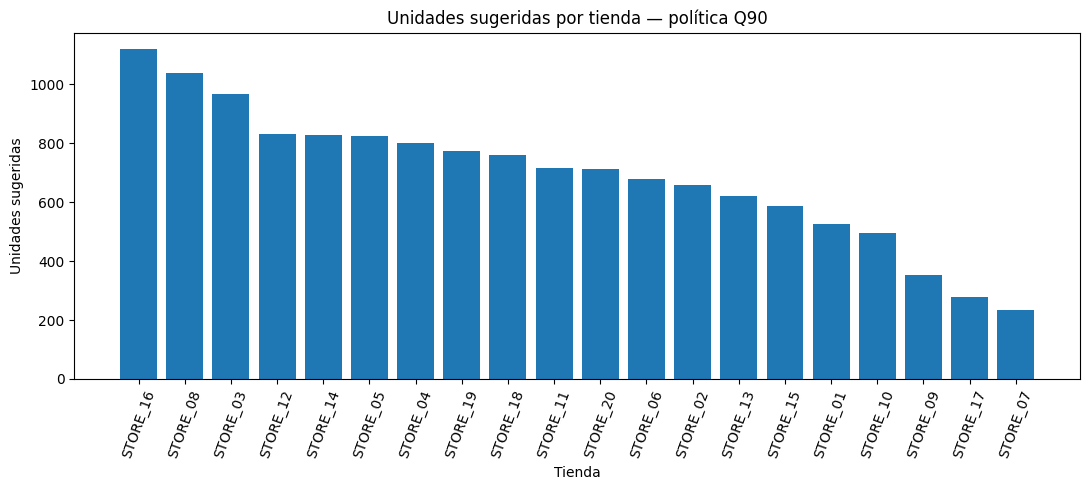

In [ ]:
by_store = (
    analysis.groupby(["id_tienda", "ciudad"], dropna=False)
    .agg(
        combinaciones=("id_producto", "nunique"),
        unidades_pedido=("pedido_sugerido", "sum"),
        valor_pedido=("valor_pedido_estimado", "sum"),
        inventario_objetivo=("inventario_objetivo", "sum"),
        demanda_7d=("demanda_pronosticada_7d", "sum")
    ).reset_index()
)
by_store["participacion_pedido"] = (
    by_store["unidades_pedido"] / max(order_units, 1)
)
by_store = by_store.sort_values("unidades_pedido", ascending=False)
display(by_store)

plt.figure(figsize=(11, 5))
plt.bar(by_store["id_tienda"], by_store["unidades_pedido"])
plt.xticks(rotation=70)
plt.title("Unidades sugeridas por tienda — política Q90")
plt.xlabel("Tienda")
plt.ylabel("Unidades sugeridas")
plt.tight_layout()
plt.show()


## 6. Distribución de pedidos por producto

Se calcula la contribución de cada producto al pedido total y al valor de compra estimado. Esto permite priorizar conversaciones con abastecimiento por referencias de alta rotación o alto impacto monetario.


,id_producto,nombre,tiendas,unidades_pedido,valor_pedido,demanda_7d,inventario_objetivo,participacion_unidades
6,PROD_007,Pastel de Pollo,20,2549,3823500,2532.000000,2902,0.184643
4,PROD_005,Buñuelo,20,2544,2035200,2562.000000,2937,0.184281
5,PROD_006,Croissant,20,2095,2514000,2222.000000,2548,0.151757
7,PROD_008,Jugo de Naranja,20,2080,4160000,2216.000000,2542,0.150670
1,PROD_002,Café con Leche,20,1499,1798800,1605.000000,1844,0.108584
2,PROD_003,Cappuccino,20,1436,2154000,1632.000000,1871,0.104020
0,PROD_001,Tinto,20,939,751200,1178.270432,1356,0.068019
3,PROD_004,Pan de Bono,20,663,663000,979.000000,1128,0.048026


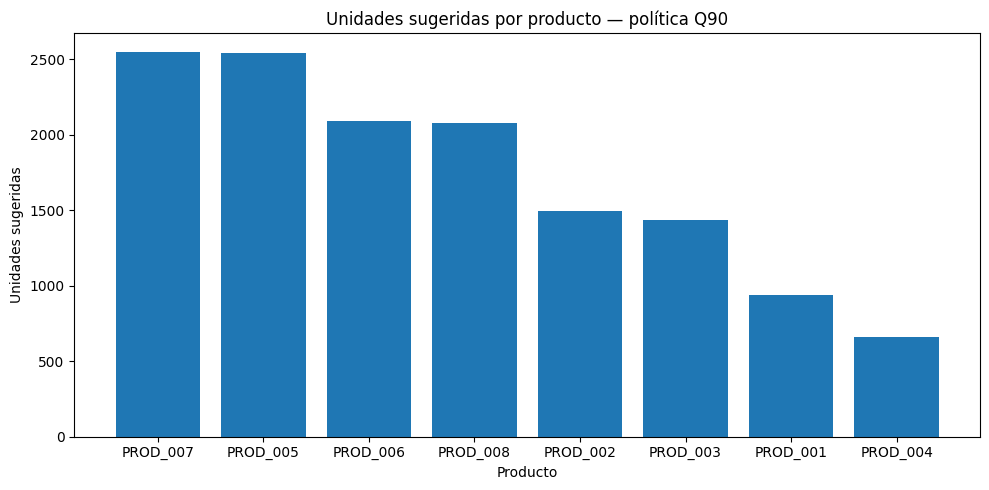

In [ ]:
by_product = (
    analysis.groupby(["id_producto", "nombre"], dropna=False)
    .agg(
        tiendas=("id_tienda", "nunique"),
        unidades_pedido=("pedido_sugerido", "sum"),
        valor_pedido=("valor_pedido_estimado", "sum"),
        demanda_7d=("demanda_pronosticada_7d", "sum"),
        inventario_objetivo=("inventario_objetivo", "sum")
    ).reset_index()
)
by_product["participacion_unidades"] = (
    by_product["unidades_pedido"] / max(order_units, 1)
)
by_product = by_product.sort_values("unidades_pedido", ascending=False)
display(by_product)

plt.figure(figsize=(10, 5))
plt.bar(by_product["id_producto"], by_product["unidades_pedido"])
plt.title("Unidades sugeridas por producto — política Q90")
plt.xlabel("Producto")
plt.ylabel("Unidades sugeridas")
plt.tight_layout()
plt.show()


## 7. ¿Dónde existe inventario suficiente?

Se compara el stock actual con la demanda puntual de siete días y con el inventario objetivo Q90.

- **Stock suficiente frente al forecast:** stock actual igual o superior a la demanda pronosticada.
- **Stock por debajo del objetivo:** stock actual inferior al inventario objetivo Q90.
- **Pedido positivo:** resultado de la política después de descontar stock actual.

Estas clasificaciones no prueban que se vaya a producir un quiebre: no tenemos ventas perdidas, disponibilidad diaria ni calendario de recepción.


In [ ]:
analysis["stock_cubre_forecast_7d"] = (
    analysis["stock_actual"] >= analysis["demanda_pronosticada_7d"]
)
analysis["stock_alcanza_objetivo_Q90"] = (
    analysis["stock_actual"] >= analysis["inventario_objetivo"]
)

stock_diagnosis = pd.DataFrame([
    ["Stock actual cubre forecast puntual de 7 días",
     int(analysis["stock_cubre_forecast_7d"].sum())],
    ["Stock actual no cubre forecast puntual de 7 días",
     int((~analysis["stock_cubre_forecast_7d"]).sum())],
    ["Stock actual alcanza objetivo Q90",
     int(analysis["stock_alcanza_objetivo_Q90"].sum())],
    ["Stock actual por debajo de objetivo Q90",
     int((~analysis["stock_alcanza_objetivo_Q90"]).sum())],
    ["Combinaciones con pedido sugerido positivo", combos_order]
], columns=["Condición", "Combinaciones"])
display(stock_diagnosis)


,Condición,Combinaciones
0,Stock actual cubre forecast puntual de 7 días,6
1,Stock actual no cubre forecast puntual de 7 días,154
2,Stock actual alcanza objetivo Q90,6
3,Stock actual por debajo de objetivo Q90,154
4,Combinaciones con pedido sugerido positivo,154


## 8. Señales de riesgo de sobreinventario

Se construyen señales para revisión operativa, no etiquetas definitivas:

1. Stock actual con más de 8 días de cobertura promedio.
2. Inventario objetivo superior al forecast semanal.
3. Pedido sugerido alto respecto a la demanda semanal.

El umbral de ocho días es coherente con el supuesto de política utilizado en el Notebook 04. La cobertura calculada es aproximada y no considera demanda variable por día.


In [ ]:
analysis["stock_mas_8_dias_cobertura"] = (
    analysis["cobertura_stock_dias"] > 8
)
analysis["objetivo_supera_demanda_semanal"] = (
    analysis["inventario_objetivo"] > analysis["demanda_pronosticada_7d"]
)
analysis["pedido_mayor_50pct_demanda"] = (
    analysis["pedido_sugerido"] > 0.5 * analysis["demanda_pronosticada_7d"]
)

risk_summary = pd.DataFrame([
    ["Stock actual > 8 días de cobertura", int(analysis["stock_mas_8_dias_cobertura"].sum())],
    ["Objetivo Q90 > demanda pronosticada de 7 días",
     int(analysis["objetivo_supera_demanda_semanal"].sum())],
    ["Pedido > 50% de demanda pronosticada semanal",
     int(analysis["pedido_mayor_50pct_demanda"].sum())]
], columns=["Señal para revisión", "Combinaciones"])
display(risk_summary)

risk_detail = analysis[
    analysis["stock_mas_8_dias_cobertura"]
    | analysis["objetivo_supera_demanda_semanal"]
    | analysis["pedido_mayor_50pct_demanda"]
].sort_values(["valor_pedido_estimado", "pedido_sugerido"], ascending=False)

display(risk_detail[[
    "id_tienda", "id_producto", "nombre", "demanda_pronosticada_7d",
    "stock_actual", "cobertura_stock_dias", "inventario_objetivo",
    "pedido_sugerido", "valor_pedido_estimado"
]].head(30))


,Señal para revisión,Combinaciones
0,Stock actual > 8 días de cobertura,6
1,Objetivo Q90 > demanda pronosticada de 7 días,160
2,Pedido > 50% de demanda pronosticada semanal,144


,id_tienda,id_producto,nombre,demanda_pronosticada_7d,stock_actual,cobertura_stock_dias,inventario_objetivo,pedido_sugerido,valor_pedido_estimado
1,STORE_08,PROD_007,Pastel de Pollo,277.0,56.0,1.415162,317,261,391500
6,STORE_05,PROD_008,Jugo de Naranja,179.0,12.0,0.469274,205,193,386000
12,STORE_04,PROD_008,Jugo de Naranja,176.0,36.0,1.431818,202,166,332000
19,STORE_16,PROD_008,Jugo de Naranja,147.0,16.0,0.761905,168,152,304000
4,STORE_03,PROD_007,Pastel de Pollo,180.0,4.0,0.155556,206,202,303000
7,STORE_16,PROD_007,Pastel de Pollo,175.0,7.0,0.280000,200,193,289500
8,STORE_06,PROD_007,Pastel de Pollo,199.0,37.0,1.301508,228,191,286500
24,STORE_03,PROD_008,Jugo de Naranja,127.0,4.0,0.220472,146,142,284000
11,STORE_12,PROD_007,Pastel de Pollo,155.0,1.0,0.045161,178,177,265500
32,STORE_06,PROD_008,Jugo de Naranja,117.0,3.0,0.179487,134,131,262000


## 9. Comparación de políticas Q85, Q90 y Q95 por combinación

Se comprueba si Q90 y Q95 producen exactamente las mismas recomendaciones, y cuántas combinaciones están limitadas por el tope de cobertura. Esto ayuda a explicar por qué los totales agregados pueden coincidir.


In [ ]:
policy_detail = policies.copy()
policy_detail["politica"] = policy_detail["politica"].astype(str)

pivot_orders = policy_detail.pivot_table(
    index=KEYS, columns="politica", values="pedido_sugerido", aggfunc="first"
).reset_index()

for p in ["Q85", "Q90", "Q95"]:
    if p not in pivot_orders.columns:
        pivot_orders[p] = np.nan

pivot_orders["delta_Q90_vs_Q85"] = pivot_orders["Q90"] - pivot_orders["Q85"]
pivot_orders["delta_Q95_vs_Q90"] = pivot_orders["Q95"] - pivot_orders["Q90"]

comparison_diagnostics = pd.DataFrame([
    ["Combinaciones Q90 distinto de Q85",
     int((pivot_orders["delta_Q90_vs_Q85"] != 0).sum())],
    ["Combinaciones Q95 distinto de Q90",
     int((pivot_orders["delta_Q95_vs_Q90"] != 0).sum())],
    ["Unidades adicionales Q90 vs Q85",
     int(pivot_orders["delta_Q90_vs_Q85"].sum())],
    ["Unidades adicionales Q95 vs Q90",
     int(pivot_orders["delta_Q95_vs_Q90"].sum())]
], columns=["Comparación", "Resultado"])
display(comparison_diagnostics)

display(pivot_orders.sort_values("delta_Q90_vs_Q85", ascending=False).head(20))


,Comparación,Resultado
0,Combinaciones Q90 distinto de Q85,18
1,Combinaciones Q95 distinto de Q90,0
2,Unidades adicionales Q90 vs Q85,65
3,Unidades adicionales Q95 vs Q90,0


politica,id_tienda,id_producto,Q85,Q90,Q95,delta_Q90_vs_Q85,delta_Q95_vs_Q90
124,STORE_16,PROD_005,267,277,277,10,0
84,STORE_11,PROD_005,189,196,196,7,0
28,STORE_04,PROD_005,158,163,163,5,0
156,STORE_20,PROD_005,126,131,131,5,0
36,STORE_05,PROD_005,151,156,156,5,0
12,STORE_02,PROD_005,93,97,97,4,0
116,STORE_15,PROD_005,59,63,63,4,0
100,STORE_13,PROD_005,99,103,103,4,0
44,STORE_06,PROD_005,104,107,107,3,0
68,STORE_09,PROD_005,55,58,58,3,0


## 10. Sensibilidad del pedido al límite de cobertura

Se muestra el cambio en unidades sugeridas al operar con topes de 7, 8 y 9 días. Los resultados se leen como escenarios de política, no como capacidad real de cada tienda.


,cobertura_maxima_dias,pedido_total_unidades_Q90,inventario_objetivo_total_Q90
0,7,11640,14932
1,8,13805,17128
2,9,15173,18515


,cobertura_maxima_dias,pedido_total_unidades_Q90,inventario_objetivo_total_Q90,variacion_unidades_vs_escenario_anterior,variacion_pct_vs_escenario_anterior
0,7,11640,14932,NaN,NaN
1,8,13805,17128,2165.0,18.599656
2,9,15173,18515,1368.0,9.909453


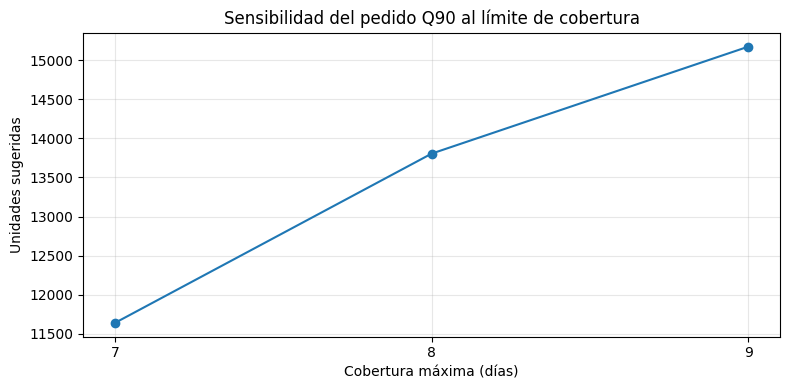

In [ ]:
coverage = coverage.sort_values("cobertura_maxima_dias")
display(coverage)

if len(coverage) > 1:
    coverage["variacion_unidades_vs_escenario_anterior"] = (
        coverage["pedido_total_unidades_Q90"].diff()
    )
    coverage["variacion_pct_vs_escenario_anterior"] = (
        coverage["pedido_total_unidades_Q90"].pct_change() * 100
    )
    display(coverage)

plt.figure(figsize=(8, 4))
plt.plot(coverage["cobertura_maxima_dias"],
         coverage["pedido_total_unidades_Q90"], marker="o")
plt.title("Sensibilidad del pedido Q90 al límite de cobertura")
plt.xlabel("Cobertura máxima (días)")
plt.ylabel("Unidades sugeridas")
plt.xticks(coverage["cobertura_maxima_dias"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Priorización de revisión con abastecimiento

Se priorizan combinaciones por valor estimado de compra y volumen sugerido. Esta lista no es una orden automática: sirve para validar referencias de mayor impacto antes de liberar pedidos.


In [ ]:
priority_review = analysis.sort_values(
    ["valor_pedido_estimado", "pedido_sugerido"], ascending=False
).copy()

priority_review["participacion_valor_acumulada"] = (
    priority_review["valor_pedido_estimado"].cumsum()
    / max(priority_review["valor_pedido_estimado"].sum(), 1)
)
display(priority_review[[
    "id_tienda", "ciudad", "id_producto", "nombre",
    "demanda_pronosticada_7d", "stock_actual", "inventario_objetivo",
    "pedido_sugerido", "costo_unitario", "valor_pedido_estimado",
    "participacion_valor_acumulada"
]].head(30))


,id_tienda,ciudad,id_producto,nombre,demanda_pronosticada_7d,stock_actual,inventario_objetivo,pedido_sugerido,costo_unitario,valor_pedido_estimado,participacion_valor_acumulada
1,STORE_08,Bogotá,PROD_007,Pastel de Pollo,277.0,56.0,317,261,1500,391500,0.021872
6,STORE_05,Bogotá,PROD_008,Jugo de Naranja,179.0,12.0,205,193,2000,386000,0.043436
12,STORE_04,Cali,PROD_008,Jugo de Naranja,176.0,36.0,202,166,2000,332000,0.061984
19,STORE_16,Bogotá,PROD_008,Jugo de Naranja,147.0,16.0,168,152,2000,304000,0.078968
4,STORE_03,Bogotá,PROD_007,Pastel de Pollo,180.0,4.0,206,202,1500,303000,0.095895
7,STORE_16,Bogotá,PROD_007,Pastel de Pollo,175.0,7.0,200,193,1500,289500,0.112069
8,STORE_06,Bogotá,PROD_007,Pastel de Pollo,199.0,37.0,228,191,1500,286500,0.128075
24,STORE_03,Bogotá,PROD_008,Jugo de Naranja,127.0,4.0,146,142,2000,284000,0.143941
11,STORE_12,Medellín,PROD_007,Pastel de Pollo,155.0,1.0,178,177,1500,265500,0.158774
32,STORE_06,Bogotá,PROD_008,Jugo de Naranja,117.0,3.0,134,131,2000,262000,0.173411


## 12. Conclusiones para la toma de decisiones

Completa la lectura con los resultados calculados en las celdas anteriores:

- **Concentración:** identificar las tiendas y productos con mayor participación en unidades y valor de compra.
- **Inventario disponible:** distinguir combinaciones con stock suficiente para el forecast puntual de aquellas que requieren protección adicional.
- **Riesgo de sobreinventario:** revisar coberturas altas y pedidos grandes relativos a la demanda.
- **Política:** confirmar si Q90 aporta una diferencia operativa frente a Q85 y Q95.
- **Cobertura:** validar con abastecimiento si un día adicional de protección es razonable por lead time y frecuencia de reposición.

No presentar como ahorro real el costo esperado simulado del Notebook 04. Para estimar impacto financiero se necesita una simulación histórica de la política, demanda no censurada, lead time, calendario de pedidos, recepción y costos completos de faltante/exceso.


## 13. Exportación de entregables

Se exportan:
- detalle SKU–Tienda enriquecido;
- resumen por tienda;
- resumen por producto;
- diagnóstico de inventario;
- señales de riesgo;
- comparación de políticas;
- sensibilidad de cobertura;
- top de revisión operativa.

Estos archivos pueden alimentar el dashboard ejecutivo y la presentación final.


In [ ]:
outputs = {
    "05_detalle_abastecimiento_Q90.csv": analysis,
    "05_resumen_por_tienda_Q90.csv": by_store,
    "05_resumen_por_producto_Q90.csv": by_product,
    "05_diagnostico_stock_Q90.csv": stock_diagnosis,
    "05_senales_riesgo_inventario_Q90.csv": risk_detail,
    "05_comparacion_politicas_Q85_Q90_Q95.csv": pivot_orders,
    "05_sensibilidad_cobertura_Q90.csv": coverage,
    "05_prioridad_revision_abastecimiento.csv": priority_review
}
for filename, df in outputs.items():
    df.to_csv(filename, index=False)
    print(f"Exportado: {filename} | filas: {len(df)}")


Exportado: 05_detalle_abastecimiento_Q90.csv | filas: 160
Exportado: 05_resumen_por_tienda_Q90.csv | filas: 20
Exportado: 05_resumen_por_producto_Q90.csv | filas: 8
Exportado: 05_diagnostico_stock_Q90.csv | filas: 5
Exportado: 05_senales_riesgo_inventario_Q90.csv | filas: 160
Exportado: 05_comparacion_politicas_Q85_Q90_Q95.csv | filas: 160
Exportado: 05_sensibilidad_cobertura_Q90.csv | filas: 3
Exportado: 05_prioridad_revision_abastecimiento.csv | filas: 160


## 14. Limitaciones y próximos datos requeridos

Para convertir el prototipo en una política operacional se requiere incorporar:

1. Lead time por proveedor, producto y tienda.
2. Pedidos en tránsito y recepciones programadas.
3. Frecuencia y calendario de revisión/reposición.
4. Restricciones de compra: mínimos, múltiplos, cajas y unidades por empaque.
5. Capacidad de almacenamiento real por tienda y familia/SKU.
6. Perecibilidad, vida útil, merma y devoluciones.
7. Ventas perdidas o indicadores de disponibilidad para corregir demanda censurada.
8. Costos completos de faltante y exceso, incluido capital, merma y markdown.

**Cierre:** el Notebook 05 permite auditar y explicar la política Q90 con los datos disponibles. No reemplaza las reglas operativas ni la aprobación de abastecimiento. La recomendación debe tratarse como piloto sujeto a validación.
